In [12]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max

# 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

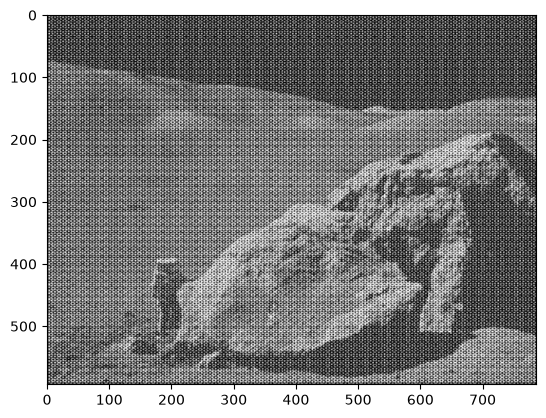

In [6]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')

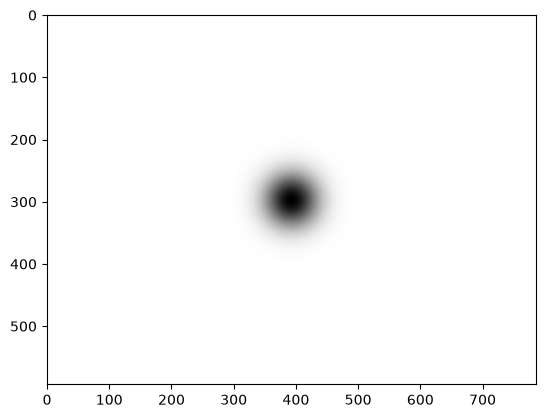

In [7]:


h, w = img.shape
centerX, centerY = (int(h/2), int(w/2))

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

sigma = 30
y, x = np.ogrid[:h, :w]
D2 = (y - centerX)**2 + (x - centerY)**2
gauss_lp = np.exp(-D2 / (2*sigma**2))
gauss_hp = 1 - gauss_lp 

plt.imshow(gauss_hp, cmap='gray')


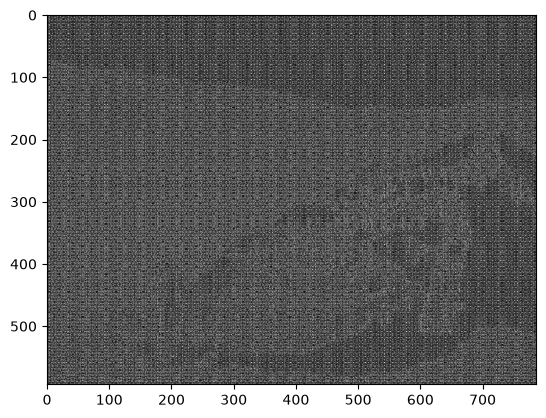

In [8]:
mask = np.zeros((h, w, 2), np.float32)
mask[:,:,0] = gauss_hp
mask[:,:,1] = gauss_hp 
dft_shift_hp = dft_shift * mask

f_ishift = np.fft.ifftshift(dft_shift_hp)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.imshow(img_back, cmap='gray')

# 2. Реализуйте вычисление свертки с помощью преобразования Фурье

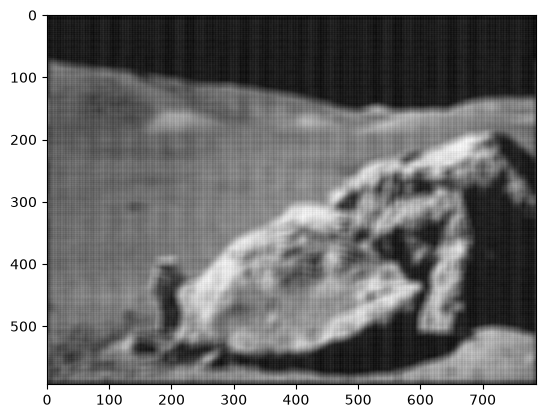

In [9]:
ksize = 15
kernel = np.ones((ksize, ksize), np.float32) / (ksize*ksize)

kernel_padded = np.zeros((h, w), np.float32)
kernel_padded[:ksize, :ksize] = kernel
kernel_padded = np.roll(kernel_padded, -(ksize//2), axis=0)
kernel_padded = np.roll(kernel_padded, -(ksize//2), axis=1)


dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_product = cv.mulSpectrums(dft_img, dft_kernel, 0) 

conv_result = cv.idft(dft_product, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)
plt.imshow(conv_result, cmap='gray')

# 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

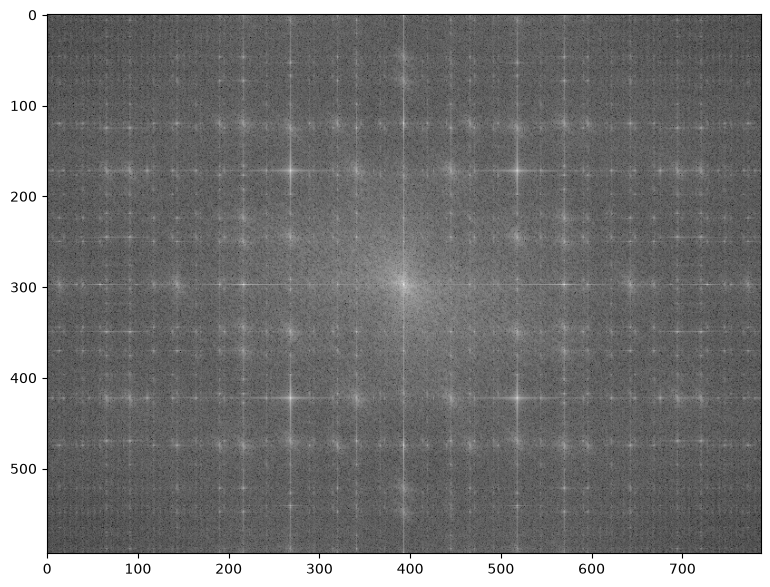

In [10]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
magnitude_spectrum = 20*np.log1p(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))
plt.figure(figsize=(10, 7))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.show()

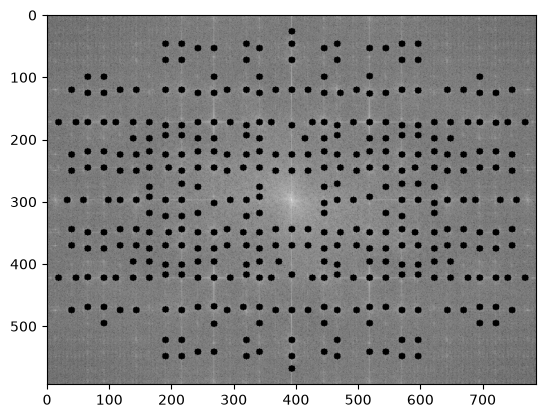

In [13]:
rows, cols = img.shape
centerX, centerY = rows // 2, cols // 2

local_max = peak_local_max(magnitude_spectrum,min_distance=15,threshold_abs=220)

mask = np.ones((rows, cols, 2), dtype=np.uint8)


radius = min(rows, cols) * 0.05
for y, x in local_max:
    distance = np.sqrt((x - centerY)**2 + (y - centerX)**2)
    if distance > radius:
        cv.circle(mask, (x, y), 5, (0, 0), -1)
        cv.circle(mask, ((cols-x) % cols, (rows-y) % rows), 5, (0, 0), -1)


filtered_dft = dft_shift * mask

filtered_spectrum = 20 * np.log(cv.magnitude(filtered_dft[:,:,0], filtered_dft[:,:,1]) + 1)

plt.imshow(filtered_spectrum, cmap='gray')
plt.show()

In [14]:
f_ishift = np.fft.ifftshift(filtered_dft, axes=(0, 1))
img_idft = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

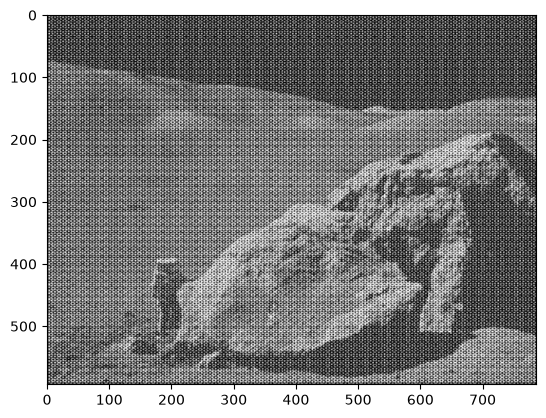

In [15]:
plt.imshow(img, cmap='gray')

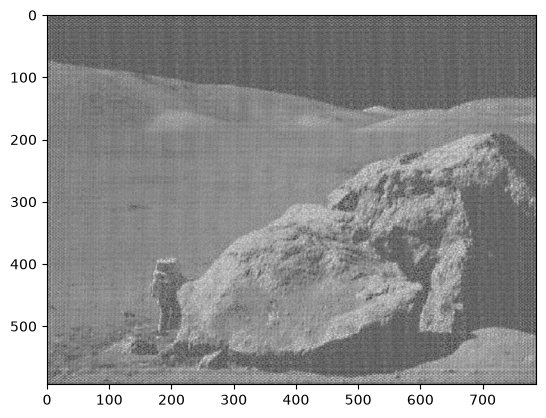

In [16]:
plt.imshow(img_idft, cmap='gray')